In [21]:
import os 
import numpy as np
import matplotlib.pyplot as plt
import random
import math
import json
from typing import Dict, List, Tuple

import torch
from torch import nn, optim
from torch.utils.data import DataLoader, random_split, Subset

import torchvision
from torchvision import transforms
from torchvision.models import efficientnet_b2, EfficientNet_B2_Weights

from sklearn.metrics import confusion_matrix, roc_curve, ConfusionMatrixDisplay, auc

def set_seed(seed=42):
    np.random.seed(seed)
    random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


set_seed()

criterion = nn.CrossEntropyLoss()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("python: 3.11.9")
print("torch:", torch.__version__)
print("cuda:", torch.version.cuda)
print("torchvision:", torchvision.__version__)
print(f"device: {device}")


python: 3.11.9
torch: 2.5.1+cu121
cuda: 12.1
torchvision: 0.20.1+cu121
device: cuda


In [ ]:
# Рукописная CNN, используемая в качестве Baseline
class MyCNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, 3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(64, 128, 3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(128, 256, 3, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.AdaptiveAvgPool2d((1, 1))
        )

        self.classifier = nn.Sequential(nn.Flatten(),
                                        nn.Linear(256, 256),
                                        nn.BatchNorm1d(256),
                                        nn.Dropout(p=0.35),
                                        nn.ReLU(),
                                        nn.Linear(256, 2)
                                        )

    def forward(self, x):
        return self.classifier(self.features(x))

# Остановка обучения в случае если val accuracy не растёт (защищает от переобучения)    
class EarlyStopping:
    def __init__(self, patience=5, min_delta=0.0):
        self.patience = patience
        self.min_delta = min_delta
        self.best_score = None
        self.best_state = None
        self.counter = 0

    def step(self, score, model):
        if self.best_score is None:
            self.best_score = score
            self.best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            return False
        
        if score > self.best_score + self.min_delta:
            self.best_score = score
            self.best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            self.counter = 0
            return False
        
        self.counter += 1
        return self.counter >= self.patience

    def restore_best(self, model):
        if self.best_state is not None:
            model.load_state_dict(self.best_state)

# Считает accuracy
def accuracy_from_logits(logits: torch.Tensor, y_true: torch.Tensor) -> float:
    preds = torch.argmax(logits, dim=1)
    return (preds == y_true).float().mean().item()

# Обучение одной эпохи
def train_one_epoch(model, loader, optimizer, criterion):
    model.train()
    total_loss, total_correct, total_seen = 0.0, 0, 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)

        optimizer.zero_grad(set_to_none=True)
        logits = model(x)
        loss = criterion(logits, y)

        if not torch.isfinite(loss):
            return float("nan"), float("nan")

        loss.backward()
        optimizer.step()

        bs = y.size(0)
        total_loss += loss.item() * bs
        total_correct += (torch.argmax(logits, dim=1) == y).sum().item()
        total_seen += bs

    return total_loss / total_seen, total_correct / total_seen

# Оценка accuracy и loss модели 
@torch.no_grad()
def evaluate(model, loader, criterion):
    model.eval()
    total_loss, total_correct, total_seen = 0.0, 0, 0

    for x, y in loader:
        x, y = x.to(device), y.to(device)
        logits = model(x)
        loss = criterion(logits, y)

        if not torch.isfinite(loss):
            return float("nan"), float("nan")

        bs = y.size(0)
        total_loss += loss.item() * bs
        total_correct += (torch.argmax(logits, dim=1) == y).sum().item()
        total_seen += bs

    return total_loss / total_seen, total_correct / total_seen

# Обучение модели
def fit(model, train_loader, val_loader, optimizer, criterion, epochs: int = 5, verbose: bool = True, early_stopping: EarlyStopping=None):
    history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}

    for epoch in range(1, epochs + 1):
        tr_loss, tr_acc = train_one_epoch(model, train_loader, optimizer, criterion)
        val_loss, val_acc = evaluate(model, val_loader, criterion)

        history["train_loss"].append(tr_loss)
        history["train_acc"].append(tr_acc)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)

        if verbose:
            print(
                f"Epoch {epoch:02d}/{epochs} | "
                f"train loss {tr_loss:.4f}, acc {tr_acc:.3f} | "
                f"val loss {val_loss:.4f}, acc {val_acc:.3f}"
            )

        if (not math.isfinite(tr_loss)) or (not math.isfinite(val_loss)):
            print("NaN/Inf в loss – обычно это признак проблем с LR/стабильностью. Останавливаем обучение.")
            break

        if early_stopping is not None:
            if early_stopping.step(val_acc, model):
                if verbose:
                    print(f"Остановка на эпохе {epoch};\nСворачиваем всю порнографиб, лучший результат: val_acc={early_stopping.best_score}")
                early_stopping.restore_best(model)
                break

    return history

# Вывод графиков обучения модели
def plot_history(hist: Dict[str, List[float]], title: str = "") -> None:
    epochs = list(range(1, len(hist["train_loss"]) + 1))

    plt.figure(figsize=(10, 4))
    plt.plot(epochs, hist["train_loss"], label="train loss")
    plt.plot(epochs, hist["val_loss"], label="val loss")
    plt.xlabel("epoch")
    plt.ylabel("loss")
    plt.title(title + " | loss")
    plt.grid(True)
    plt.legend()
    plt.show()

    plt.figure(figsize=(10, 4))
    plt.plot(epochs, hist["train_acc"], label="train acc")
    plt.plot(epochs, hist["val_acc"], label="val acc")
    plt.xlabel("epoch")
    plt.ylabel("accuracy")
    plt.title(title + " | accuracy")
    plt.grid(True)
    plt.legend()
    plt.show()

# Получение весов предобученой модели
def get_efficientnet_b2_weights():
    # Пытаемся взять предобученные веса. Если не получилось – вернем None.
    try:
        w = EfficientNet_B2_Weights.DEFAULT
        return w
    except Exception as e:
        print("Не удалось получить веса ResNet18_Weights.DEFAULT. Причина:", repr(e))
        return None

# Замена классификатора у модели
def replace_classifier(model, classifier: nn.Sequential=None):
    if hasattr(model, "fc"):  # ResNet
        if classifier is None:
            model.fc = nn.Linear(model.fc.in_features, 2)
        else:
            model.fc = classifier
    elif hasattr(model, "classifier"):
        if isinstance(model.classifier, nn.Sequential):
            if classifier is None:
                model.classifier = nn.Sequential(nn.Flatten(),
                                                    nn.Linear(1408, 256),
                                                    nn.BatchNorm1d(256),
                                                    nn.Dropout(p=0.35),
                                                    nn.ReLU(),
                                                    nn.Linear(256, 2)
                                                    )
            else:
                model.classifier = classifier
        else:
            raise NotImplementedError
    else:
        raise NotImplementedError
    return model

# Получение предобученной модели
def build_efficientnet_b2(weights=get_efficientnet_b2_weights(), classifier: nn.Sequential=None) -> nn.Module:
    try:
        model = efficientnet_b2(weights=weights)
    except Exception as e:
        print("Не удалось загрузить предобученные веса. Переходим на weights=None. Причина:", repr(e))
        model = efficientnet_b2(weights=None)

    return replace_classifier(model, classifier)

# Настройка обучаемости уровней модели (заморозка)
def set_requires_grad(module: nn.Module, flag: bool) -> None:
    for p in module.parameters():
        p.requires_grad = flag

# Отрисовка матрицы ошибок
def plot_confusion_matrix(model, dataloader, device, class_names=None):
    model.eval()

    all_preds = []
    all_labels = []

    with torch.no_grad():
        for x, y in dataloader:
            x = x.to(device)
            y = y.to(device)

            outputs = model(x)
            preds = torch.argmax(outputs, dim=1)

            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(y.cpu().numpy())

    # считаем confusion matrix
    cm = confusion_matrix(all_labels, all_preds)

    # визуализация
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
    
    fig, ax = plt.subplots(figsize=(6, 6))
    disp.plot(ax=ax, cmap="Blues", colorbar=True)
    plt.title("Confusion Matrix")
    plt.show()

# Отрисовка ROC кривой
def plot_roc_curve(model, dataloader, device):
    model.eval()

    all_probs = []
    all_labels = []

    with torch.no_grad():
        for x, y in dataloader:
            x = x.to(device)

            outputs = model(x)
            
            # превращаем logits в вероятности
            probs = torch.softmax(outputs, dim=1)
            
            # берём вероятность положительного класса (класс 1)
            pos_probs = probs[:, 1]

            all_probs.extend(pos_probs.cpu().numpy())
            all_labels.extend(y.numpy())

    all_probs = np.array(all_probs)
    all_labels = np.array(all_labels)

    # ROC
    fpr, tpr, thresholds = roc_curve(all_labels, all_probs)
    roc_auc = auc(fpr, tpr)

    # plot
    plt.figure(figsize=(6, 6))
    plt.plot(fpr, tpr, label=f"AUC = {roc_auc:.4f}")
    plt.plot([0, 1], [0, 1], linestyle="--")  # случайная модель
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title("ROC Curve")
    plt.legend()
    plt.grid()
    plt.show()

    return fpr, tpr, roc_auc


In [5]:
baseline = MyCNN().to(device)

In [6]:
efficientnet = build_efficientnet_b2().to(device)

In [7]:
train_aug_transform = transforms.Compose([
    transforms.Resize(293),
    transforms.RandomResizedCrop(256, scale=(0.8, 1.0)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.1, contrast=0.1, saturation=0.1),
    transforms.ToTensor(),
    transforms.RandomErasing(p=0.15),
    transforms.Normalize((0.485, 0.456, 0.406), (0.229, 0.224, 0.225)),
])

test_transform = transforms.Compose([
    transforms.Resize(293),
    transforms.CenterCrop(256),
    transforms.ToTensor(),
    transforms.Normalize((0.485, 0.456, 0.406), (0.229, 0.224, 0.225)),
])

train_ds = torchvision.datasets.ImageFolder(root="data/RealVsFakeFaces/train", transform=train_aug_transform)
val_ds = torchvision.datasets.ImageFolder(root="data/RealVsFakeFaces/valid", transform=test_transform)
test_ds = torchvision.datasets.ImageFolder(root="data/RealVsFakeFaces/test", transform=test_transform)

train_loader = DataLoader(train_ds, batch_size=64, shuffle=True)
val_loader = DataLoader(val_ds, batch_size=64, shuffle=False)
test_loader = DataLoader(test_ds, batch_size=64, shuffle=False)

print(f'classes: {train_ds.classes}')
print(f'train: {len(train_ds)}')
print(f'val: {len(val_ds)}')
print(f'test: {len(test_ds)}')


classes: ['fake', 'real']
train: 6000
val: 2000
test: 2000


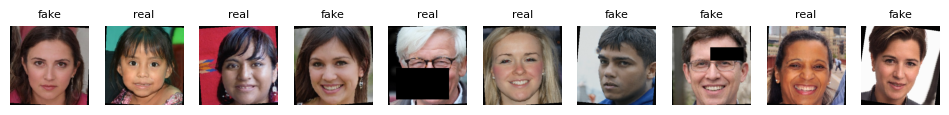

In [5]:
def denorm(x: torch.Tensor) -> torch.Tensor:
    # x: (C,H,W), нормализованный
    mean = torch.tensor((0.485, 0.456, 0.406)).view(3, 1, 1)
    std = torch.tensor((0.229, 0.224, 0.225)).view(3, 1, 1)
    return x * std + mean


def show_batch(loader ,num: int):
    x_batch, y_batch = next(iter(loader))[:num]
    plt.figure(figsize=(12, 2))
    for i in range(num):
        plt.subplot(1, num, i + 1)
        img = denorm(x_batch[i]).clamp(0, 1).permute(1, 2, 0).numpy()
        plt.imshow(img)
        plt.title(train_ds.classes[y_batch[i].item()], fontsize=8)
        plt.axis("off")
    plt.show()

show_batch(train_loader, 10)

Epoch 01/20 | train loss 0.7107, acc 0.550 | val loss 0.6780, acc 0.570
Epoch 02/20 | train loss 0.6918, acc 0.565 | val loss 0.7024, acc 0.566
Epoch 03/20 | train loss 0.6803, acc 0.581 | val loss 0.6794, acc 0.574
Epoch 04/20 | train loss 0.6682, acc 0.603 | val loss 0.7714, acc 0.539
Epoch 05/20 | train loss 0.6665, acc 0.604 | val loss 0.6825, acc 0.549
Epoch 06/20 | train loss 0.6533, acc 0.623 | val loss 0.7029, acc 0.583
Epoch 07/20 | train loss 0.6423, acc 0.628 | val loss 0.7630, acc 0.536
Epoch 08/20 | train loss 0.6383, acc 0.629 | val loss 0.6480, acc 0.637
Epoch 09/20 | train loss 0.6320, acc 0.648 | val loss 0.7147, acc 0.614
Epoch 10/20 | train loss 0.6312, acc 0.645 | val loss 0.6804, acc 0.600
Epoch 11/20 | train loss 0.6219, acc 0.660 | val loss 0.6214, acc 0.652
Epoch 12/20 | train loss 0.6044, acc 0.667 | val loss 0.6259, acc 0.654
Epoch 13/20 | train loss 0.5969, acc 0.684 | val loss 0.6118, acc 0.670
Epoch 14/20 | train loss 0.5924, acc 0.690 | val loss 0.6021, ac

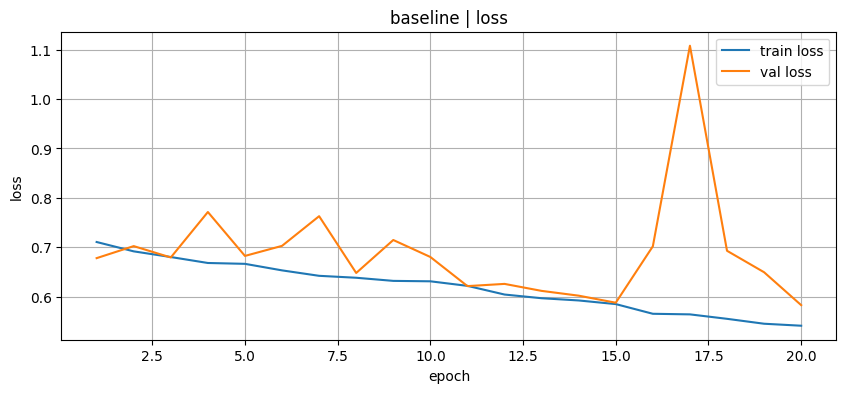

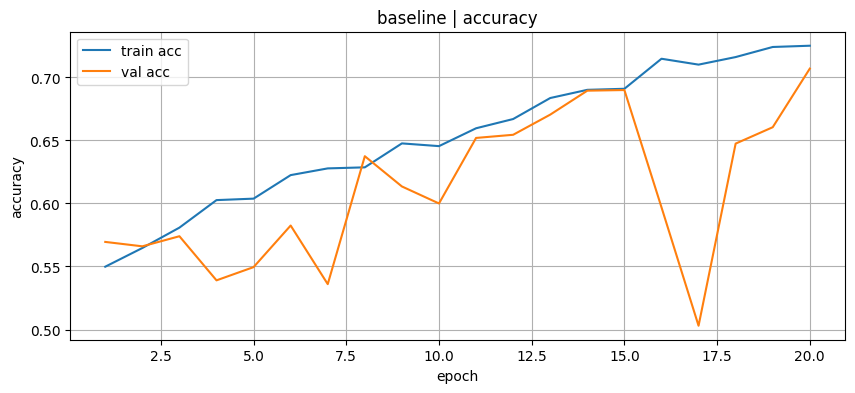

In [9]:
optimizer_Bl = optim.Adam(baseline.parameters(), lr= 5 * 1e-4)

histBl = fit(baseline, train_loader, val_loader, optimizer_Bl, criterion, 20, early_stopping=EarlyStopping())
plot_history(histBl, "baseline")

Epoch 01/20 | train loss 0.5542, acc 0.719 | val loss 0.5198, acc 0.734
Epoch 02/20 | train loss 0.4989, acc 0.759 | val loss 0.4878, acc 0.750
Epoch 03/20 | train loss 0.4820, acc 0.772 | val loss 0.4756, acc 0.763
Epoch 04/20 | train loss 0.4697, acc 0.776 | val loss 0.4605, acc 0.778
Epoch 05/20 | train loss 0.4650, acc 0.773 | val loss 0.5089, acc 0.752
Epoch 06/20 | train loss 0.4659, acc 0.776 | val loss 0.4446, acc 0.785
Epoch 07/20 | train loss 0.4472, acc 0.786 | val loss 0.4470, acc 0.782
Epoch 08/20 | train loss 0.4543, acc 0.784 | val loss 0.4558, acc 0.773
Epoch 09/20 | train loss 0.4466, acc 0.789 | val loss 0.4772, acc 0.769
Epoch 10/20 | train loss 0.4453, acc 0.790 | val loss 0.4716, acc 0.771
Epoch 11/20 | train loss 0.4371, acc 0.792 | val loss 0.4501, acc 0.791
Epoch 12/20 | train loss 0.4401, acc 0.797 | val loss 0.5019, acc 0.771
Epoch 13/20 | train loss 0.4344, acc 0.793 | val loss 0.4549, acc 0.784
Epoch 14/20 | train loss 0.4334, acc 0.796 | val loss 0.4560, ac

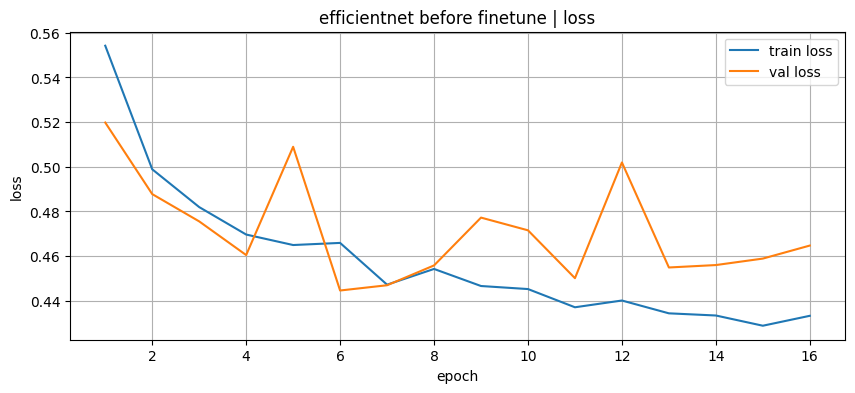

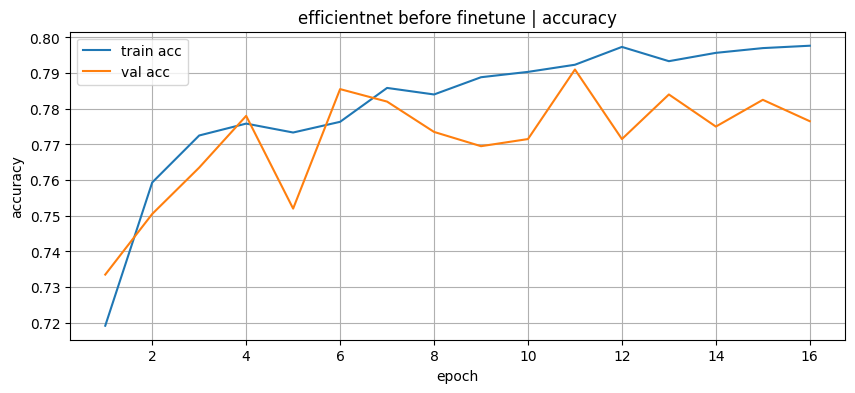

In [35]:
set_requires_grad(efficientnet, False)
set_requires_grad(efficientnet.classifier, True)

optimizer_Ef = optim.Adam(efficientnet.classifier.parameters(), lr=5 * 1e-4)

hist_Ef = fit(efficientnet, train_loader, val_loader, optimizer_Ef, criterion, 20, early_stopping=EarlyStopping())
plot_history(hist_Ef, "efficientnet before finetune")
torch.save(efficientnet.state_dict(), "./artifacts/efficientnet_before_finetune.pt")

Epoch 01/20 | train loss 0.4450, acc 0.789 | val loss 0.4539, acc 0.779
Epoch 02/20 | train loss 0.4105, acc 0.813 | val loss 0.4443, acc 0.795
Epoch 03/20 | train loss 0.4035, acc 0.820 | val loss 0.4284, acc 0.800
Epoch 04/20 | train loss 0.3826, acc 0.823 | val loss 0.4183, acc 0.806
Epoch 05/20 | train loss 0.3638, acc 0.836 | val loss 0.3851, acc 0.832
Epoch 06/20 | train loss 0.3512, acc 0.842 | val loss 0.3786, acc 0.833
Epoch 07/20 | train loss 0.3281, acc 0.856 | val loss 0.3888, acc 0.824
Epoch 08/20 | train loss 0.3269, acc 0.858 | val loss 0.3457, acc 0.848
Epoch 09/20 | train loss 0.3095, acc 0.863 | val loss 0.3545, acc 0.845
Epoch 10/20 | train loss 0.2966, acc 0.874 | val loss 0.3448, acc 0.849
Epoch 11/20 | train loss 0.2945, acc 0.874 | val loss 0.3767, acc 0.840
Epoch 12/20 | train loss 0.2847, acc 0.878 | val loss 0.3601, acc 0.848
Epoch 13/20 | train loss 0.2611, acc 0.889 | val loss 0.3739, acc 0.843
Epoch 14/20 | train loss 0.2534, acc 0.895 | val loss 0.3215, ac

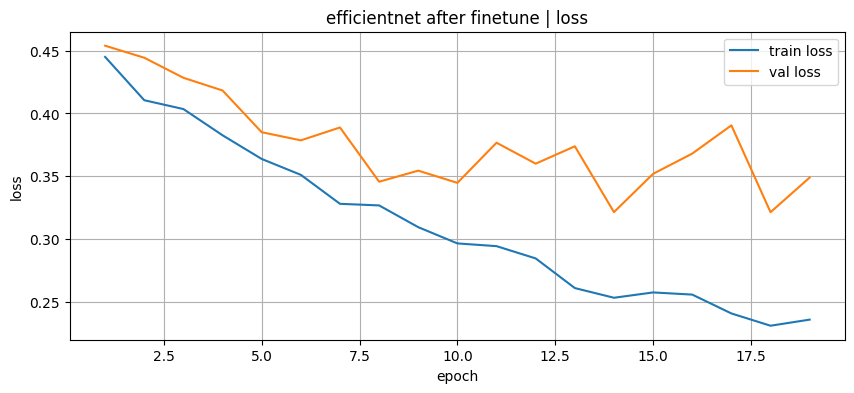

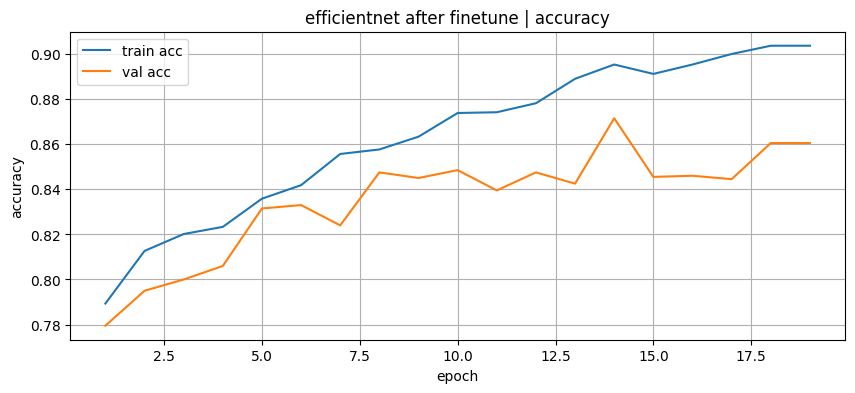

In [37]:
set_requires_grad(efficientnet.features[-1], True)

params = [
    {"params": efficientnet.features[-1].parameters(), "lr": 1e-4},
    {"params": efficientnet.classifier.parameters(), "lr": 5 * 1e-4},
]

optimizer = optim.Adam(params, weight_decay=1e-4)

histC4 = fit(efficientnet, train_loader, val_loader, optimizer, criterion, 20, early_stopping=EarlyStopping())
plot_history(histC4, "efficientnet after finetune")

In [38]:
torch.save(efficientnet.state_dict(), "./artifacts/efficientnet_after_finetune.pt")

In [9]:
efficientnet.load_state_dict(torch.load("./artifacts/efficientnet_after_finetune.pt", map_location="cuda"))

C:\Users\user\AppData\Local\Temp\ipykernel_12824\2877552707.py:1: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  efficientnet.load_state_dict(torch.load("./artifacts/efficien

<All keys matched successfully>

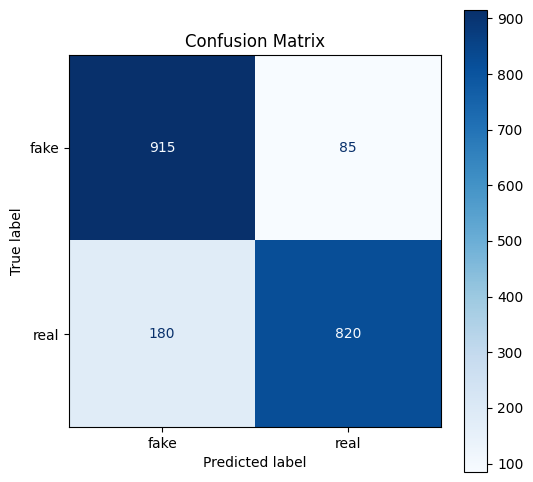

In [13]:
plot_confusion_matrix(efficientnet, test_loader, device, train_ds.classes)

precision и recal полученной модели:
     
       precision   recal    f1

Fake |   0.836   | 0.915 | 0.874

Real |   0.906   | 0.82  | 0.861

In [16]:
print(f'Точность на test выборке: {evaluate(efficientnet, test_loader, criterion)[1]}')

Точность на test выборке: 0.8675


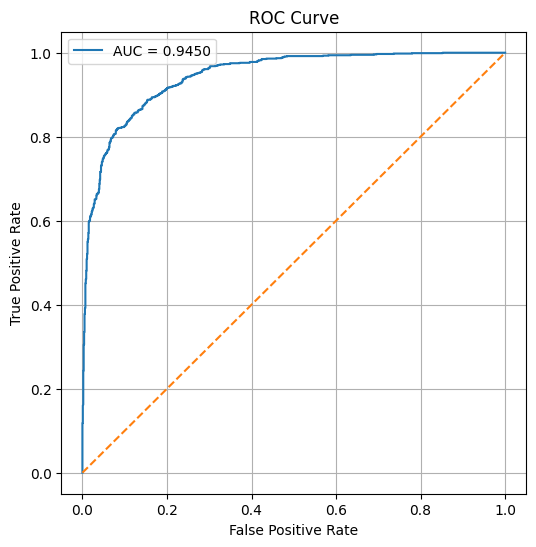

(array([0.   , 0.   , 0.   , 0.   , 0.   , 0.   , 0.   , 0.   , 0.   ,
        0.   , 0.   , 0.   , 0.   , 0.   , 0.   , 0.   , 0.001, 0.001,
        0.001, 0.001, 0.001, 0.001, 0.001, 0.001, 0.001, 0.001, 0.001,
        0.001, 0.001, 0.001, 0.001, 0.001, 0.002, 0.002, 0.002, 0.002,
        0.002, 0.002, 0.002, 0.002, 0.002, 0.002, 0.002, 0.002, 0.002,
        0.002, 0.002, 0.002, 0.002, 0.002, 0.002, 0.002, 0.002, 0.002,
        0.002, 0.002, 0.002, 0.002, 0.002, 0.002, 0.003, 0.003, 0.003,
        0.003, 0.003, 0.003, 0.003, 0.003, 0.003, 0.004, 0.004, 0.005,
        0.005, 0.006, 0.006, 0.007, 0.007, 0.008, 0.008, 0.009, 0.009,
        0.01 , 0.01 , 0.011, 0.011, 0.011, 0.011, 0.012, 0.012, 0.013,
        0.013, 0.014, 0.014, 0.015, 0.015, 0.016, 0.016, 0.017, 0.017,
        0.018, 0.018, 0.019, 0.019, 0.02 , 0.02 , 0.021, 0.021, 0.022,
        0.022, 0.023, 0.023, 0.024, 0.024, 0.025, 0.025, 0.027, 0.027,
        0.028, 0.028, 0.029, 0.029, 0.032, 0.032, 0.033, 0.033, 0.034,
      

In [22]:
plot_roc_curve(efficientnet, test_loader, device)